In [1]:
import polars as pl
import numpy as np
from datetime import date
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, RobustScaler
# Import requested libraries

In [2]:
df = pl.read_csv("../data/processed/online_retail_clean.csv", try_parse_dates = True)
# Read the dataset

In [3]:
df = df.with_columns(
    (pl.lit(date(2010, 12, 10)) - df["invoice_date"]).alias("recency")
)
# Calculate the recency of each customer's last purchase

In [4]:
frequency = df.group_by("customer_id").agg(
    pl.col("invoice").n_unique().alias("frequency")
)
# Calculate the number of unique invoices for each customer

In [5]:
df = df.with_columns(
    (pl.col("quantity") * pl.col("price")).alias("monetary")
)
# Calculate the monetary value of each transaction

In [6]:
customer_monetary = df.group_by("customer_id").agg(
    pl.col("monetary").sum().alias("total_monetary")
)
# Calculate the total monetary value for each customer

In [7]:
# Keep only positive-quantity transactions for RFM analysis.
df_rfm = df.filter(pl.col("quantity") > 0)

rfm = df_rfm.group_by("customer_id").agg(
    (date(2010, 12, 10) - pl.col("invoice_date").max()).dt.total_days().alias("recency"),
    pl.col("invoice").n_unique().alias("frequency"),
    pl.col("monetary").sum().alias("total_monetary")
)
rfm
# Calculate RFM metrics for each customer

customer_id,recency,frequency,total_monetary
i64,i64,u32,f64
17974,17,3,1035.1
13535,38,1,89.5
14032,2,6,1874.68
17248,117,1,181.89
13047,9,17,5557.62
…,…,…,…
13406,63,2,568.92
13722,56,7,3260.0
15059,12,10,2153.48


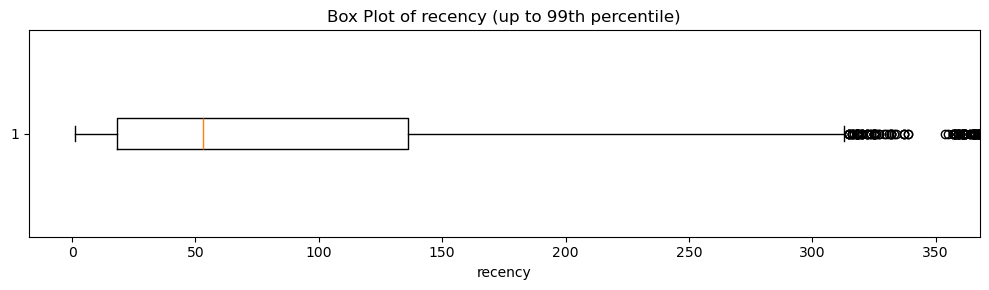

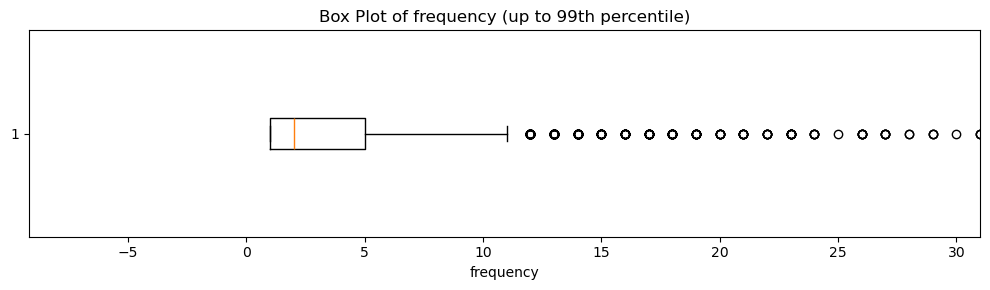

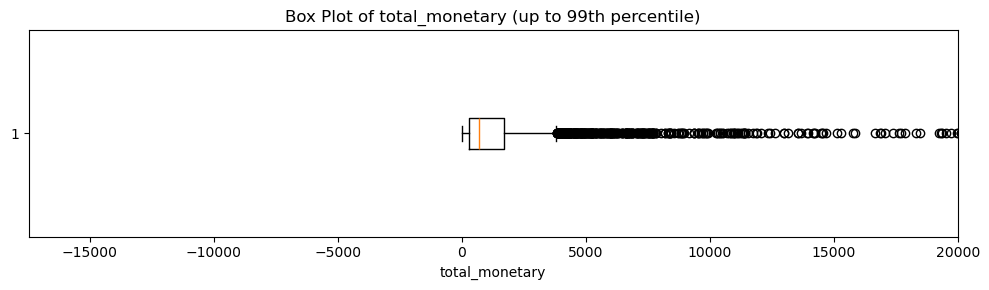

In [8]:
columns = ["recency","frequency", "total_monetary"]

for column in columns:
    values = rfm[column].to_numpy()

    # Set the upper limit at the 99th percentile for visualization
    upper_limit = np.percentile(values, 99)

    plt.figure(figsize = (10, 3))
    plt.boxplot(values, vert = False)
    plt.xlim(right = upper_limit)
    plt.title(f"Box Plot of {column} (up to 99th percentile)")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

In [9]:
rfm.select(["recency","frequency","total_monetary"]).describe()
# Inspect the distribution of RFM metrics

statistic,recency,frequency,total_monetary
str,f64,f64,f64
"""count""",4314.0,4314.0,4314.0
"""null_count""",0.0,0.0,0.0
"""mean""",91.269819,4.454103,2039.460766
"""std""",96.944304,8.168658,8909.797773
"""min""",1.0,1.0,0.0
"""25%""",18.0,1.0,307.1
"""50%""",53.0,2.0,701.61
"""75%""",136.0,5.0,1713.69
"""max""",374.0,205.0,349164.35


In [10]:
# Check for non-positive monetary values.
rfm.filter(
    pl.col("total_monetary") <= 0
)

customer_id,recency,frequency,total_monetary
i64,i64,u32,f64
14827,301,1,0.0
14103,301,1,0.0


In [11]:
# Calculate skewness for RFM metrics.
rfm.select(
    pl.col("recency").skew().alias("recency_skewness"),
    pl.col("frequency").skew().alias("frequency_skewness"),
    pl.col("total_monetary").skew().alias("monetary_skewness")
)

recency_skewness,frequency_skewness,monetary_skewness
f64,f64,f64
1.280272,10.544837,23.996835


In [12]:
# Apply log1p transformation to RFM metrics.
rfm_transformed = rfm.with_columns(
    (pl.col("recency") + 1).log().alias("recency_log"),
    (pl.col("frequency") + 1).log().alias("frequency_log"),
    (pl.col("total_monetary") + 1).log().alias("monetary_log")
)

In [13]:
# Calculate skewness after log transformation
rfm_transformed.select(
    pl.col("recency_log").skew(),
    pl.col("frequency_log").skew(),
    pl.col("monetary_log").skew()
)

recency_log,frequency_log,monetary_log
f64,f64,f64
-0.424996,1.181713,0.205556


In [14]:
# Select the transformed RFM features for clustering
rfm_features = rfm_transformed.select(
    "recency",
    "frequency_log",
    "monetary_log"
)

In [15]:
# Convert the RFM features into a NumPy array.
X = rfm_features.to_numpy()

# Apply StandardScaler.
standard_scaler = StandardScaler()
X_standard = standard_scaler.fit_transform(X)

# Apply RobustScaler.
robust_scaler = RobustScaler()
X_robust = robust_scaler.fit_transform(X)